# Evidential regression: train, validate, then test

This small CPU tutorial trains the package's `DNN` with its original
`EvidentialRegressionLoss` on a synthetic nonlinear problem with varying noise.
It requires no downloads and takes about a minute on a typical CPU. The goal is
to demonstrate a reproducible workflow, not to reproduce the paper's weather benchmark.

Install the package and notebook dependencies in your Python 3.11 environment:
`python -m pip install -e ".[torch,notebooks]"`. Select that environment's Jupyter
kernel, then **Restart Kernel and Run All**. The notebook uses the installed package
and works from either the repository root or the notebook directory.

The 60% training set fits scalers and model weights. The 20% validation set chooses
the checkpoint. The remaining 20% test set is opened only after the model is frozen;
its results are diagnostics, never a signal for choosing a better run.


Based on the original MILES-GUESS examples by John Schreck, David John Gagne, Charlie Becker, Gabrielle Gantos, Dhamma Kimpara, and Thomas Martin. This modernized tutorial uses new synthetic data and preserves the package's scientific loss.


In [1]:
import copy
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 2026
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
device = torch.device("cpu")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | "
      f"NumPy {np.__version__} | SciPy {scipy.__version__} | device: {device}")

from mlguess.torch.models import DNN
from mlguess.torch.regression_losses import EvidentialRegressionLoss
from mlguess.evaluation import evaluate_nig


Python 3.11.17 | PyTorch 2.14.1+cpu | NumPy 2.4.6 | SciPy 1.17.1 | device: cpu


## 1. Generate data and reserve independent rows

Here each row is an independent observation, so a random split is appropriate.
For weather stations, repeated subjects, or time series, replace this with a group
or chronological split before fitting anything. The known generating mean and noise
are available only because this is a synthetic demonstration.


Rows: train=1260, validation=420, reserved test=420


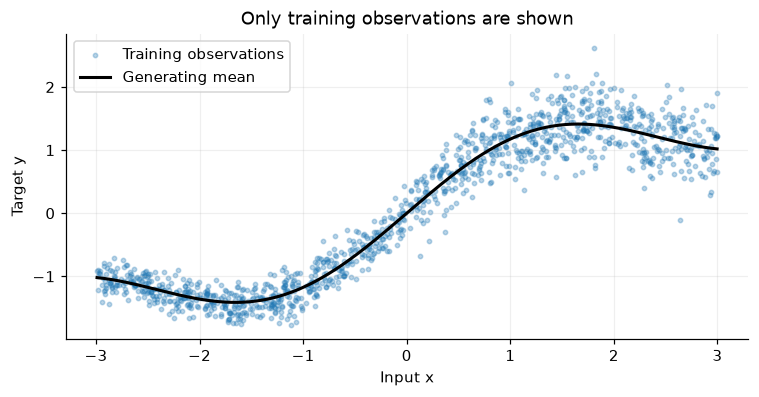

In [2]:
rng = np.random.default_rng(SEED)
X = rng.uniform(-3.0, 3.0, size=(2100, 1))
latent_mean = 0.5 * X[:, 0] + 0.7 * np.sin(1.3 * X[:, 0])
noise_sd = 0.15 + 0.20 / (1.0 + np.exp(-1.5 * X[:, 0]))
y = (latent_mean + rng.normal(size=len(X)) * noise_sd)[:, None]

development, test_idx = train_test_split(np.arange(len(X)), test_size=0.20, random_state=SEED)
train_idx, valid_idx = train_test_split(development, test_size=0.25, random_state=SEED + 1)
assert not (set(train_idx) & set(valid_idx) or set(train_idx) & set(test_idx)
            or set(valid_idx) & set(test_idx))
print(f"Rows: train={len(train_idx)}, validation={len(valid_idx)}, reserved test={len(test_idx)}")

x_scaler = StandardScaler().fit(X[train_idx])
y_scaler = StandardScaler().fit(y[train_idx])
as_tensor = lambda array: torch.as_tensor(array, dtype=torch.float32, device=device)
x_train = as_tensor(x_scaler.transform(X[train_idx]))
y_train = as_tensor(y_scaler.transform(y[train_idx]))
x_valid = as_tensor(x_scaler.transform(X[valid_idx]))
y_valid = as_tensor(y_scaler.transform(y[valid_idx]))
loader = DataLoader(TensorDataset(x_train, y_train), batch_size=128, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED), num_workers=0)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(X[train_idx, 0], y[train_idx, 0], s=8, alpha=0.3, label="Training observations")
order = np.argsort(X[train_idx, 0])
ax.plot(X[train_idx[order], 0], latent_mean[train_idx[order]], color="black",
        linewidth=2, label="Generating mean")
ax.set(xlabel="Input x", ylabel="Target y", title="Only training observations are shown")
ax.legend(); plt.show()


## 2. Fit the original NIG loss and select by validation NLL

The head returns $(\gamma,\nu,\alpha,\beta)$. We retain the package's original
negative log likelihood plus evidence regularizer, with a fixed coefficient of 0.01.
Validation uses predictive negative log likelihood without that regularizer, so
checkpoint selection measures the predictive distribution. All settings are fixed
before looking at test results. Losses below are in standardized target units.


Frozen validation-selected epoch 148; trained 188 epochs in 4.2 s. No test predictions made yet.


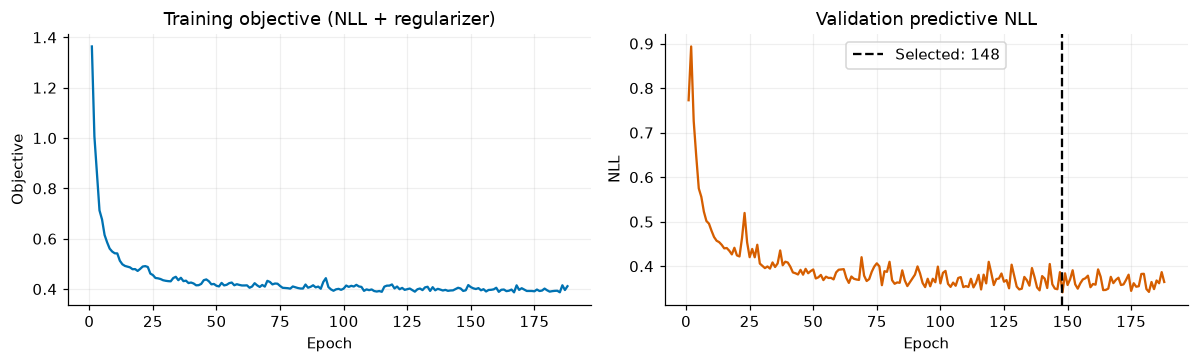

In [3]:
torch.manual_seed(SEED)
model = DNN(input_size=1, output_size=1, layer_size=[64, 64], dr=[0.0, 0.0],
            batch_norm=False, lng=True).to(device)
criterion = EvidentialRegressionLoss(coef=0.01)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
max_epochs, patience = 220, 40
history, best_score, best_epoch, best_state = [], float("inf"), 0, None
started = time.perf_counter()

for epoch in range(1, max_epochs + 1):
    model.train()
    loss_sum = 0.0
    for xb, yb in loader:
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(*model(xb), yb)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss")
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(xb)
    model.eval()
    with torch.no_grad():
        gamma, nu, alpha, beta = model(x_valid)
        valid_nll = criterion.normal_inverse_gamma_nll(y_valid, gamma, nu, alpha, beta).mean().item()
    history.append({"epoch": epoch, "train_objective": loss_sum / len(x_train), "valid_nll": valid_nll})
    if valid_nll < best_score:
        best_score, best_epoch, best_state = valid_nll, epoch, copy.deepcopy(model.state_dict())
    if epoch - best_epoch >= patience:
        break

assert best_state is not None
model.load_state_dict(best_state)
model.eval()
model.requires_grad_(False)
history = pd.DataFrame(history)
print(f"Frozen validation-selected epoch {best_epoch}; trained {len(history)} epochs "
      f"in {time.perf_counter() - started:.1f} s. No test predictions made yet.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(history.epoch, history.train_objective, color="#0072B2")
axes[0].set(title="Training objective (NLL + regularizer)", xlabel="Epoch", ylabel="Objective")
axes[1].plot(history.epoch, history.valid_nll, color="#D55E00")
axes[1].axvline(best_epoch, color="black", linestyle="--", label=f"Selected: {best_epoch}")
axes[1].set(title="Validation predictive NLL", xlabel="Epoch", ylabel="NLL")
axes[1].legend(); fig.tight_layout(); plt.show()


## 3. Open the test set once the model is frozen

For one NIG prediction, the law of total variance gives

$$A=\frac{\beta}{\alpha-1},\qquad
E=\frac{\beta}{\nu(\alpha-1)},\qquad T=A+E.$$

The predictive distribution is Student-t with degrees of freedom $2\alpha$ and
scale $s=\sqrt{\beta(1+\nu)/(\nu\alpha)}$. **This scale is not the predictive
standard deviation.** `evaluate_nig` converts the prediction back to target units,
then uses SciPy's Student-t `logpdf`, `cdf`, and `ppf` for NLL, PIT, and central
prediction intervals. These are intervals for a new observation, not confidence
intervals for the latent mean. Variances are multiplied by the square of the target scale.


In [4]:
x_test = as_tensor(x_scaler.transform(X[test_idx]))
with torch.no_grad():
    test_parameters = tuple(value.cpu().numpy() for value in model(x_test))
test = evaluate_nig(y[test_idx], test_parameters, y_scaler=y_scaler,
                    interval_levels=(0.50, 0.80, 0.90, 0.95))
assert np.allclose(test["total"], test["aleatoric"] + test["epistemic"])
assert np.isfinite(test["metrics"].to_numpy()).all()
display(test["metrics"].rename(index={0: "y"}).round(4))
display(test["coverage"].round(4))
print("All test metrics and intervals are in original target units.")


All test metrics and intervals are in original target units.


,mae,rmse,r2,nll
target,,,,
y,0.3206,0.3934,0.88,0.4938


,target,nominal,observed,mean_width
0,0,0.50,0.4738,0.5199
1,0,0.80,0.7976,1.0260
2,0,0.90,0.9286,1.3633
3,0,0.95,0.9762,1.6871


## 4. Inspect predictions, variance components, and residuals

The shaded band is the central 90% Student-t prediction interval. The separate
aleatoric and epistemic curves are the model's decomposition. Their names do not
guarantee that they recover the true noise and model error: regularization and model
misspecification affect that separation. The known generating noise is shown only
as a diagnostic reference, never used to rescale or calibrate predictions.


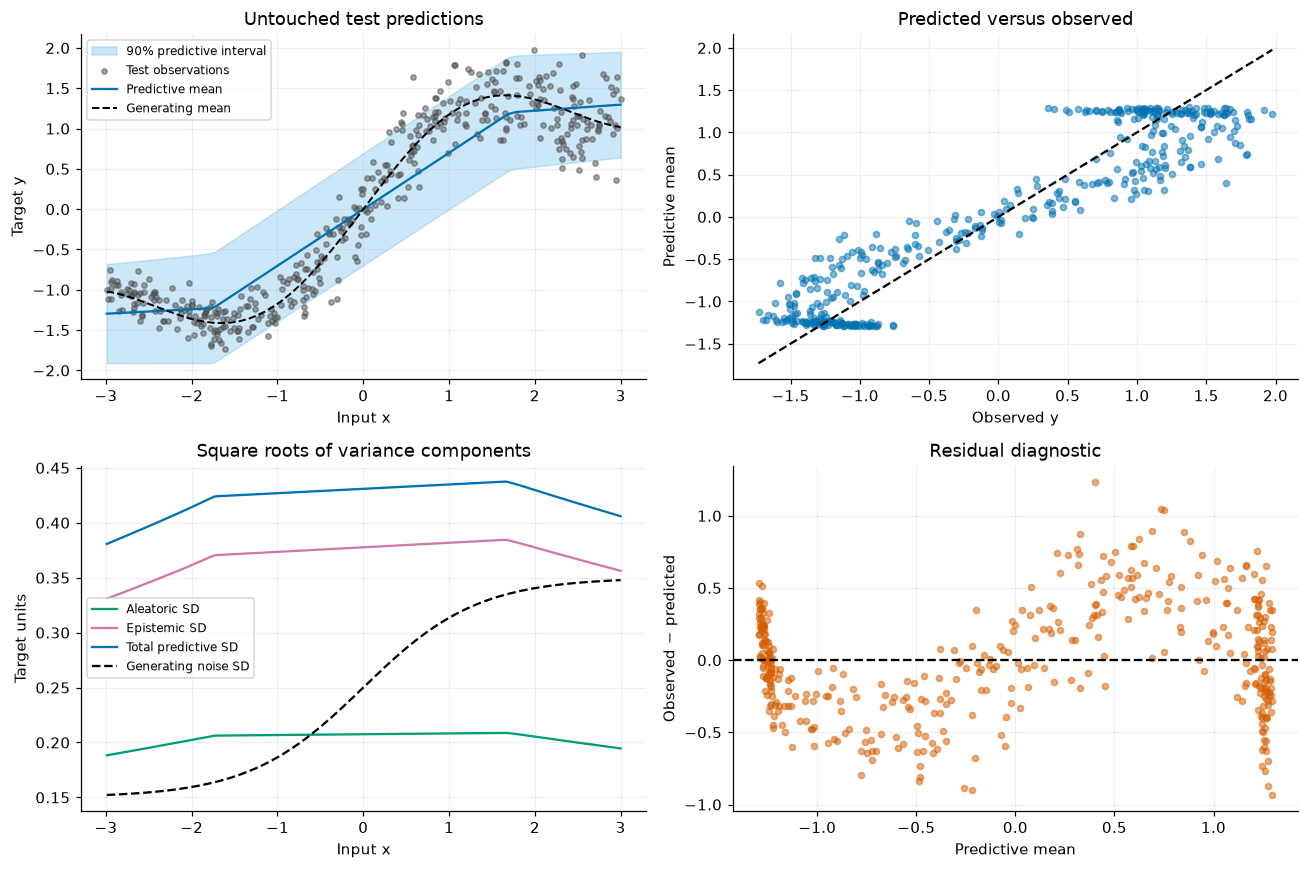

In [5]:
mean = test["mean"][:, 0]
observed = y[test_idx, 0]
test_x = X[test_idx, 0]
order = np.argsort(test_x)
lower, upper = test["intervals"][0.90]
residual = observed - mean

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ax = axes[0, 0]
ax.fill_between(test_x[order], lower[order, 0], upper[order, 0], color="#56B4E9",
                alpha=0.3, label="90% predictive interval")
ax.scatter(test_x, observed, s=12, color="0.3", alpha=0.5, label="Test observations")
ax.plot(test_x[order], mean[order], color="#0072B2", label="Predictive mean")
ax.plot(test_x[order], latent_mean[test_idx][order], color="black", linestyle="--",
        linewidth=1.3, label="Generating mean")
ax.set(title="Untouched test predictions", xlabel="Input x", ylabel="Target y")
ax.legend(fontsize=8)

ax = axes[0, 1]
ax.scatter(observed, mean, s=16, alpha=0.5, color="#0072B2")
limits = [min(observed.min(), mean.min()), max(observed.max(), mean.max())]
ax.plot(limits, limits, color="black", linestyle="--")
ax.set(title="Predicted versus observed", xlabel="Observed y", ylabel="Predictive mean")

ax = axes[1, 0]
for key, label, color in [("aleatoric", "Aleatoric SD", "#009E73"),
                           ("epistemic", "Epistemic SD", "#CC79A7"),
                           ("total", "Total predictive SD", "#0072B2")]:
    ax.plot(test_x[order], np.sqrt(test[key][order, 0]), label=label, color=color)
ax.plot(test_x[order], noise_sd[test_idx][order], "k--", label="Generating noise SD")
ax.set(title="Square roots of variance components", xlabel="Input x", ylabel="Target units")
ax.legend(fontsize=8)

ax = axes[1, 1]
ax.scatter(mean, residual, s=16, alpha=0.5, color="#D55E00")
ax.axhline(0, color="black", linestyle="--")
ax.set(title="Residual diagnostic", xlabel="Predictive mean", ylabel="Observed − predicted")
fig.tight_layout(); plt.show()


## 5. Check distributional calibration

A calibrated central $q$ interval covers approximately a fraction $q$ of independent
test outcomes. The PIT is the predictive CDF evaluated at the observed outcome; it
should be uniform for calibrated continuous predictive distributions. Sampling noise
is expected with a small test set. Neither a visually good PIT nor aggregate coverage
establishes calibration in every subgroup. If these diagnostics motivate a change,
make it using development data and evaluate on a newly reserved final test set.


In the stored run, the small network underfits some curvature and its estimated variance split does not follow the generating noise exactly. The held-out plots expose those limitations even though the variance identity is satisfied. This is a worked evaluation example, not a claim that the uncertainty components are calibrated.


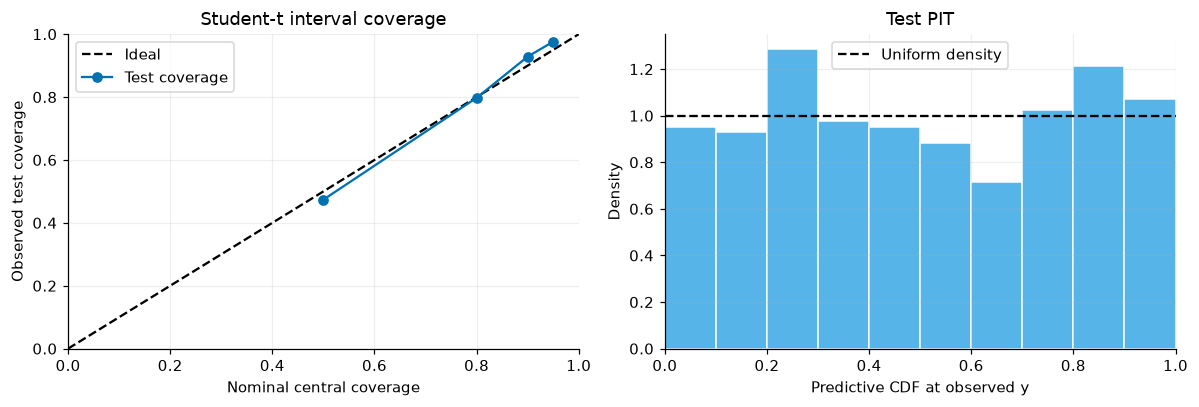

In [6]:
coverage = test["coverage"].query("target == 0")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot([0, 1], [0, 1], "k--", label="Ideal")
axes[0].plot(coverage.nominal, coverage.observed, "o-", color="#0072B2", label="Test coverage")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Nominal central coverage",
            ylabel="Observed test coverage", title="Student-t interval coverage")
axes[0].legend()
axes[1].hist(test["pit"][:, 0], bins=np.linspace(0, 1, 11), density=True,
             color="#56B4E9", edgecolor="white")
axes[1].axhline(1.0, color="black", linestyle="--", label="Uniform density")
axes[1].set(xlim=(0, 1), xlabel="Predictive CDF at observed y", ylabel="Density", title="Test PIT")
axes[1].legend(); fig.tight_layout(); plt.show()


## Apply this to your data

Replace `X` with a finite numeric feature matrix of shape `(rows, features)` and `y`
with a target matrix of shape `(rows, targets)`, and change the model's input/output
sizes accordingly. Keep the split, train-only preprocessing, validation selection,
and final test boundary. Do not include the target or post-outcome information among
the features. Use the custom-dataset tutorial for a fuller starting point.

For an ensemble, the predictive distribution is a **mixture** of Student-t distributions;
its quantiles are not obtained by averaging these single-model intervals. Use the
documented ensemble law-of-total-variance helpers for moment decomposition and a
mixture CDF (or predictive samples) for mixture intervals. This tutorial evaluates
one NIG model and therefore has no between-model variance term.

Scientific references: [Schreck et al., 2024](https://doi.org/10.1175/AIES-D-23-0093.1),
especially the regression decomposition; [Amini et al., Deep Evidential Regression](https://arxiv.org/abs/1910.02600).
Original weather workflows are retained under `notebooks/legacy/`.
